# Introduction

Pour produire 1kg d'acier, il faut utilioser entre 300 et 600 litres d'eau. L'eau est largement utilisée dans l'industrie pour refroidir les centrales, laver et alimenter les machines... Les usines consomment donc beaucoup d'eau dans leur processus de production.  
Or, les usines ont tendance à s'agglomérer autour de grands sites industriels pour des raisons d'efficacité.  
Nous pouvons donc nous demander quel est l'état des nappes phréatiques autour de ces grands sites industriels.  


Problématique : L'implantation des nouvelles méga-usines (batteries, hydrogène, data centers) se fait-elle de manière aveugle dans des bassins versants déjà condamnés à un épuisement de leurs nappes phréatiques ?

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests as rq
import numpy as np
import time
import os
import contextily as ctx

# Récupération des données

### Récupération des données sur les installations industrielles
On utilise l'API de Georisques pour récupérer les informations sur les usines.

In [2]:
#On crée le dossier data qui va stocker toutes nos données :
os.makedirs("../../data", exist_ok=True)

#On récupère la liste des installations industrielles à l'échelle nationale sur le site de l'ICPE
url_icpe = "https://mapsref.brgm.fr/wxs/georisques/georisques_dl?&service=wfs&version=2.0.0&request=getfeature&typename=InstallationsClassees&outputformat=CSVTEXT"
lien_stockage_physique_icpe = "../../data/icpe.csv"

if not os.path.exists(lien_stockage_physique_icpe):
    fichier_icpe = rq.get(url_icpe)

    if fichier_icpe.status_code == 200:
        with open(lien_stockage_physique_icpe, "wb") as f:
            f.write(fichier_icpe.content)
        print("Fichier téléchargé.")
    else:
        print("Erreur avec le téléchargement du fichier ICPE.")
else:
    print("Le fichier a déjà été téléchargé.")

Le fichier a déjà été téléchargé.


On a  136450 installations industrielles. Dont  104757 installations industrielles ICPE.
On ne garde que les  43716 installations industrielles pures.


Text(0, 0.5, "Nombre d'installations industrielles")

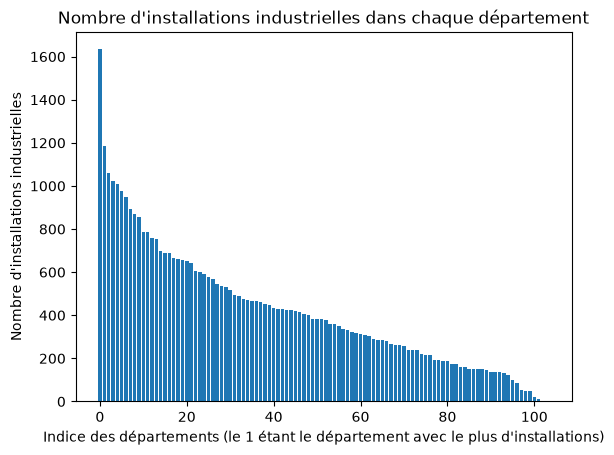

In [3]:
# On récupère donc la liste des installations industrielles
installations_indust = pd.read_csv(lien_stockage_physique_icpe, sep=";", encoding='utf-8')
print("On a ", installations_indust.shape[0], "installations industrielles.", end="")
installations_indust = installations_indust.loc[installations_indust["lib_regime"] != "Non ICPE"]
print(" Dont ", installations_indust.shape[0], "installations industrielles ICPE.")

#On veut garder uniquement les installations industrielles pures (pas l'agriculture et l'élevage par ex)
installations_indust = (installations_indust.loc[
    (installations_indust["industrie"] == 1)
    & (installations_indust["bovins"] == 0)
    & (installations_indust["porcs"] == 0)
    & (installations_indust["volailles"] == 0)
    & (installations_indust["eolienne"] == 0)
    ])
print("On ne garde que les ", installations_indust.shape[0], "installations industrielles pures.")

#On classe les départements qui ont le plus d'installations industrielles pour limiter la recherche (car les données sur Hub'eau sont trop volumineuses pour traiter la France entière)
classement_dpt = (installations_indust.groupby("num_dep")
    .size()
    .sort_values(ascending=False)
    )
plt.bar(range(classement_dpt.shape[0]), classement_dpt.values)
plt.title("Nombre d'installations industrielles dans chaque département")
plt.xlabel("Indice des départements (le 1 étant le département avec le plus d'installations)")
plt.ylabel("Nombre d'installations industrielles")

On va donc prendre le département qui contient le plus d'installations industrielles pour notre analyse.  
En effet, Hub'eau API nous donne un très grand volume de données et nous devons nous limiter dans notre recherche à quelques départements.  
Avec le graphique ci-dessus, on voit que le département 59 est de loin le plus grand centre industriel français.  
Nous nous concentrerons donc sur le département 59 pour la suite de l'analyse.  

In [4]:
departement_cible = classement_dpt.index[0]
print("Département analysé : ", departement_cible)

Département analysé :  59


Mise en forme des données géographiques avec Geopandas

In [5]:
installations_indust = installations_indust.loc[installations_indust["num_dep"] == departement_cible]

#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles du 59
nb_position_less = installations_indust.loc[installations_indust["x"].isnull() | installations_indust["y"].isnull() | installations_indust["code_epsg"].isnull()].shape[0]
print(nb_position_less, "installations industrielles n'ont pas de coordonnées géographiques.")
installations_indust = installations_indust.loc[installations_indust["x"].notnull() & installations_indust["y"].notnull() & installations_indust["code_epsg"].notnull()]

#On utilise les coordonnées des installations pour les localiser avec Geopandas
installations_indust["geometry"] = None #Colonne qui va prendre la valeur position Geopandas
codes_epsg_type_coord = installations_indust["code_epsg"].unique()   #On veut que ça marche pour les différents types de référentiels (x,y)
for epsg in codes_epsg_type_coord:
    filtre = installations_indust["code_epsg"] == epsg
    points = gpd.points_from_xy(
        installations_indust.loc[filtre, "x"], 
        installations_indust.loc[filtre, "y"]
    )
    serie_geometrique = gpd.GeoSeries(points, crs=f"EPSG:{int(epsg)}")
    serie_geometrique = serie_geometrique.to_crs("EPSG:2154") #On ramène tout sous le même format
    installations_indust.loc[filtre, "geometry"] = serie_geometrique.values

#On définit un GeoDataFrame pour les études géométriques :
installations_indust = gpd.GeoDataFrame(installations_indust, geometry="geometry", crs="EPSG:2154")

0 installations industrielles n'ont pas de coordonnées géographiques.


### Récupération des données sur les nappes phréatiques du 59

L'API Hub'eau ne permet pas d'envoyer toutes les stations d'un coup.  
Encore moins toutes les chroniques d'un coup.  
Donc on sélectionne que la région pour laquelle on a vu qu'il y avait une grande concentration d'industrie : le 59

In [9]:
#On récupère les stations de mesure des nappes phréatiques sur le site Hubeau
url_stations = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/stations"
chemin_fichier_stations = "../../data/stations_nappes.csv"

stations = []

params = {"code_departement": departement_cible, "size": 5000, "format": "json"}

if not os.path.exists(chemin_fichier_stations):
    fichier_stations = rq.get(url_stations, params=params)

    if fichier_stations.status_code == 200:
        data = fichier_stations.json()
        stations.extend(data["data"])
        print("Fichier téléchargé.")
    else:
        print(fichier_stations.status_code)
        print("Erreur avec le téléchargement du fichier stations Hubeau.")

    stations = pd.DataFrame(stations)
    stations.to_csv(chemin_fichier_stations, encoding='utf-8')
    print("On a récupéré ", stations.shape[0], "stations de mesure des nappes phréatiques dans le département ", departement_cible, ".")
else:
    stations = pd.read_csv(chemin_fichier_stations, encoding='utf-8')
    print("Le fichier a déjà été téléchargé.")

Fichier téléchargé.
On a récupéré  730 stations de mesure des nappes phréatiques dans le département  59 .


Mise en forme des données géographiques avec Geopandas

In [10]:
#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles du 59
nb_position_less = stations.loc[stations["x"].isnull() | stations["y"].isnull()].shape[0]
print(nb_position_less, "stations n'ont pas de coordonnées géographiques.")
stations = stations.loc[stations["x"].notnull() & stations["y"].notnull()]

#On crée le modèle Geopandas
stations = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations['x'], stations['y']),
    crs="EPSG:4326"
).to_crs(epsg=2154) #On ramène tout sous le même format que les installations industrielles

0 stations n'ont pas de coordonnées géographiques.


Pour chaque station identifiée dans les départements contenant le plus d'industrie, on récupère les séries temporelles de niveau des nappes phréatiques entre janvier 2015 et janvier 2026

In [11]:
chemin_fichier_chroniques = "../../data/chroniques_nappes.csv"

if not os.path.exists(chemin_fichier_chroniques):
    #On ne peut pas récupérer le volume des nappes phréatiques pour toutes les stations en même temps.


    #On veut récupérer les volumes des nappes phréatiques pour chaque station
    url_chroniques_api = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/chroniques"
    chroniques = []

    #Quand on essaye de récupérer toutes les données de toutes les nappes, on a une erreur 414 : la requête URL est trop longue avec tous les code_bss en paramètres.
    #Donc on va diviser les données de 700 stations à récupérer en paquets de 50.

    liste_codes_bss_stations = stations["code_bss"].tolist()
    paquets_intermediaires = []
    for i in range(0, stations.shape[0], 50):
        paquets_intermediaires.append(liste_codes_bss_stations[i:i+50])
    print("Nombre de stations par paquets : ", [len(x) for x in paquets_intermediaires])

    for paquet in paquets_intermediaires:
        params_api = {"code_bss":",".join(paquet), "size":5000, "format":"json", "date_debut_mesure":"2015-01-01", "date_fin_mesure":"2026-01-01"}

        #Le problème est que le volume de données retourné est trop important. => On obtient une erreur 206 pour chaque paquet.
        #Il faut donc récupérer les premières informations renvoyées par l'API et aller chercher la page suivante.
        url = url_chroniques_api
        while url != None:
            try:
                fichier_chroniques = rq.get(url, params=params_api, timeout=20)    #On met un timeout pour rapidement recommencer la requête si ça marche pas.
            except Exception as e:
                print("Erreur requête : ", end="")
                print(e)
                print("Pas grave, on va réessayer.")
                continue
            #On recommence en haut de la boucle sur la même URL
            if fichier_chroniques.status_code == 200 or fichier_chroniques.status_code == 206:
                data = fichier_chroniques.json()
                chroniques.extend(data["data"])
                url = data.get("next")
                params_api = None   #Il semble que cette information soit déjà intégrée dans l'url de la page "next"
                print("Sous-paquet téléchargé.")
                time.sleep(1)   #On attend 1 sec pour éviter de se faire rejeter par le serveur
            else:
                print(fichier_chroniques.status_code)
                print("Erreur avec le téléchargement du fichier stations Hubeau.")
                time.sleep(1)   #On attend 1 seconde et on recommence au cas où ça se répare tout seul
    print("Téléchargement des donné réussi !")

    chroniques = pd.DataFrame(chroniques)
    chroniques.to_csv(chemin_fichier_chroniques, encoding='utf-8')

else:
    chroniques = pd.read_csv(chemin_fichier_chroniques, encoding='utf-8')
    print("Le fichier a déjà été téléchargé.")

Nombre de stations par paquets :  [50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 30]


Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Erreur requête : HTTPSConnectionPool(host='hubeau.eaufrance.fr', port=443): Read timed out. (read timeout=20)
Pas grave, on va réessayer.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Erreur requête : HTTPSConnectionPool(host='hubeau.eaufrance.fr', port=443): Read timed out. (read timeout=20)
Pas grave, on va réessayer.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous

On nettoie les données des séries temporelles des nappes phréatiques

In [12]:
chroniques['date_mesure'] = pd.to_datetime(chroniques['date_mesure'])
print("Nombre de chroniques sans niveau d'eau : ", chroniques.loc[chroniques["niveau_nappe_eau"].isnull()].shape[0])
#On supprime les chroniques pour lesquelles le niveau d'eau est NULL
chroniques = chroniques.loc[chroniques["niveau_nappe_eau"].notnull()]

Nombre de chroniques sans niveau d'eau :  0


### Test des données

Un exemple de série temporelle pour une station (nappe phréatique)

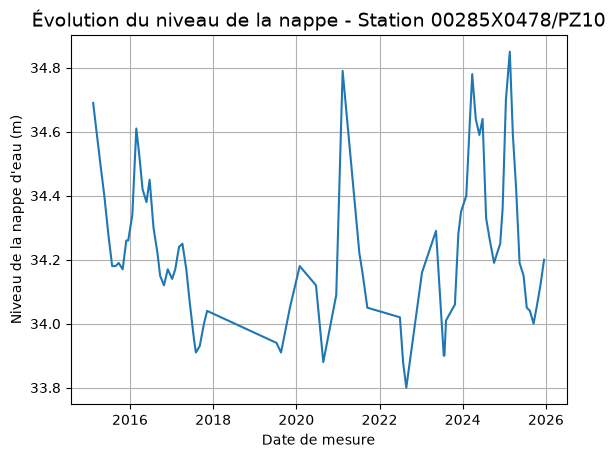

In [31]:
# Représentation d'une série temporelle d'une station
station_cible = '00285X0478/PZ10'
serie_station = chroniques.loc[chroniques['code_bss'] == station_cible]
serie_station = serie_station.sort_values(by='date_mesure')

plt.plot(serie_station['date_mesure'], serie_station['niveau_nappe_eau'])

plt.title(f"Évolution du niveau de la nappe - Station {station_cible}", fontsize=14)
plt.xlabel("Date de mesure")
plt.ylabel("Niveau de la nappe d'eau (m)")
plt.grid(True)

### Nettoyage et standardisation des données

Les séries temporelles de Hub'eau donnent des mesures des nappes phréatiques à des dates différentes entre les stations.  
Pour les calculs futurs, on va standardiser ça en faisant une moyenne par station et par mois

In [32]:
chroniques['date_mois_annee'] = chroniques['date_mesure'].dt.to_period('M')
chroniques

chroniques_niveau_mensuel = (chroniques.groupby(["code_bss", "date_mois_annee"])
              .agg({
                  "niveau_nappe_eau":"mean",
                  "profondeur_nappe":"mean"
              })
              .reset_index()
    )
chroniques_niveau_mensuel["date_mesure"] = chroniques_niveau_mensuel["date_mois_annee"].dt.to_timestamp()
chroniques_niveau_mensuel['date_mesure'] = pd.to_datetime(chroniques_niveau_mensuel['date_mesure'])
chroniques = chroniques_niveau_mensuel.copy()
print("Les données ont été normalisées en moyenne par mois pour chaque station.")

Les données ont été normalisées en moyenne par mois pour chaque station.


### Premier résultat : Répartition des usines et des stations hydrologiques dans le Nord

Text(0.5, 1.0, 'Répartition des usines ICPE et des stations hydrologiques dans le département')

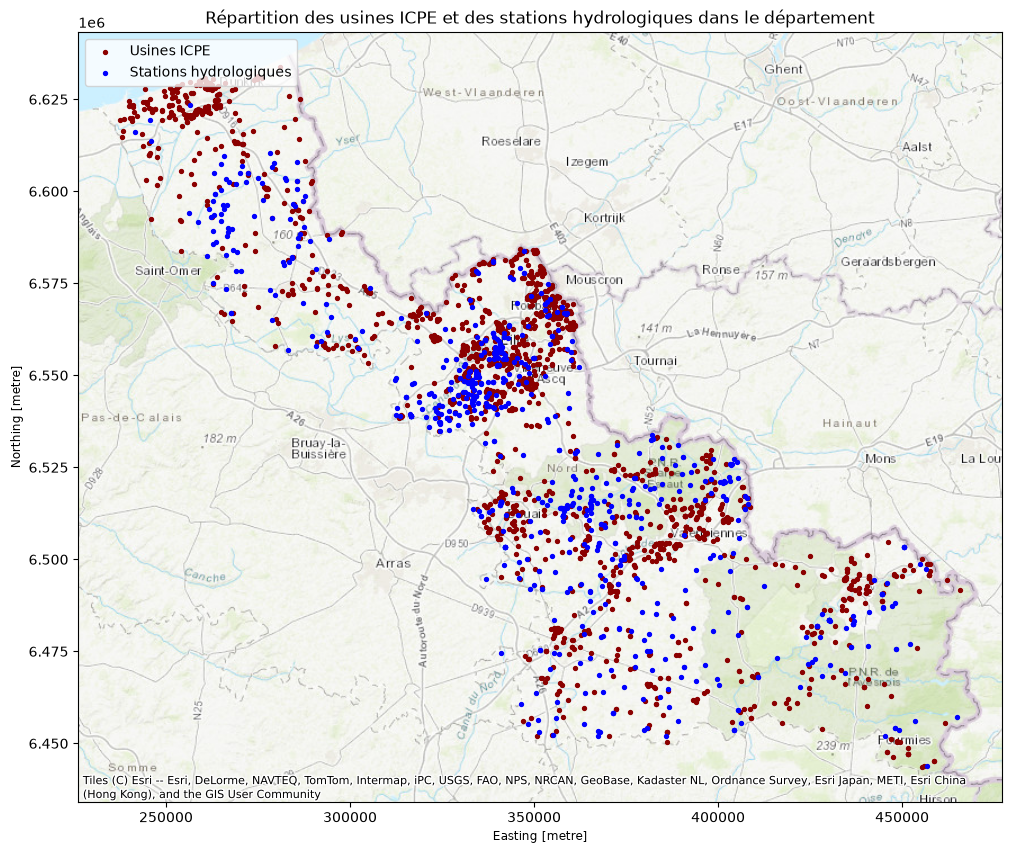

In [33]:
# Stations (points bleus, taille réduite, avec un fin contour blanc pour la lisibilité)
ax = plt.subplots(figsize=(12, 10))[1]
installations_indust.to_crs(epsg=3857).plot(ax=ax, color="darkred", markersize=8, label="Usines ICPE", zorder=1)
stations.to_crs(epsg=3857).plot(ax=ax, color="blue", markersize=8, label="Stations hydrologiques", zorder=2)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap)
plt.legend(loc="upper left")
plt.title("Répartition des usines ICPE et des stations hydrologiques dans le département")

### On cherche la quantité d'usines par station

In [34]:
#On veut le nombre d'usines qui sont dans les 5km de chaque station
r = 5 * 1000

stations_rayon = stations.copy()
stations_rayon["geometry"] = stations_rayon.geometry.buffer(r)  #On suppose que la station prend toute la place dans un rayon de 5km autour du point où elle est réellement

usines_ds_rayon = gpd.sjoin(installations_indust, stations_rayon, how="inner", predicate="within")
nb_usine_ds_rayon = usines_ds_rayon.groupby("code_bss").size().reset_index(name="nb_usines_5km")

stations = stations.merge(nb_usine_ds_rayon, on="code_bss", how="left")
stations["nb_usines_5km"] = stations["nb_usines_5km"].fillna(0).astype(int) #On remplace les valeurs nulles par 0

#On rajoute une colonne dans le tableau chroniques qui indique la pression industrielle (nb d'usines dans un rayon de 5km qui exploitent probablement la nappe)
chroniques = chroniques.merge(stations[["code_bss", "nb_usines_5km"]], on="code_bss", how="inner")


Text(0.5, 0, 'Date')

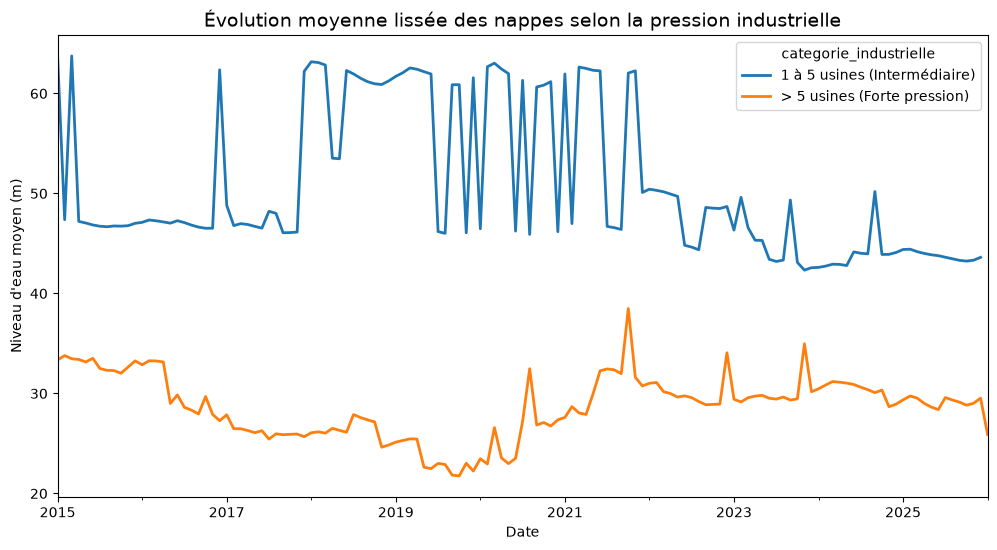

In [35]:
# Visualisation
conditions = [
    (chroniques['nb_usines_5km'] == 0),
    (chroniques['nb_usines_5km'] > 0) & (chroniques['nb_usines_5km'] <= 5),
    (chroniques['nb_usines_5km'] > 5)
]
choix = ['0 usine (Zone rurale)', '1 à 5 usines (Intermédiaire)', '> 5 usines (Forte pression)']
chroniques['categorie_industrielle'] = np.select(conditions, choix, default='Inconnu')

evolution_lisse = chroniques.groupby(['date_mois_annee', 'categorie_industrielle'])['niveau_nappe_eau'].mean().unstack()

evolution_lisse.plot(figsize=(12, 6), linewidth=2)
plt.title("Évolution moyenne lissée des nappes selon la pression industrielle", fontsize=14)
plt.ylabel("Niveau d'eau moyen (m)")
plt.xlabel("Date")

On observe que, en moyenne, les nappes qui ont plus de 5 usines à moins de 5km ont un niveau inférieur de 20m.  
Nous n'avons pourtant toujours pas établi de causalité. Les conditions géographiques et l'environnement peuvent également affecter ces nappes.

Les nappes phréatiques sont affectées majoritairement par 3 choses :  
- L'altitude, la topographie et la géologie  
- La pluie  
- L'industrie

## I. On va d'abord s'intéresser aux conditions géographiques de la nappe

## 1. Prise en compte de l'effet de l'altitude de la nappe

1. Commençons par un état des lieux de l'altitude des différentes stations.

Text(0.5, 1.0, 'Altitude des stations hydrologiques')

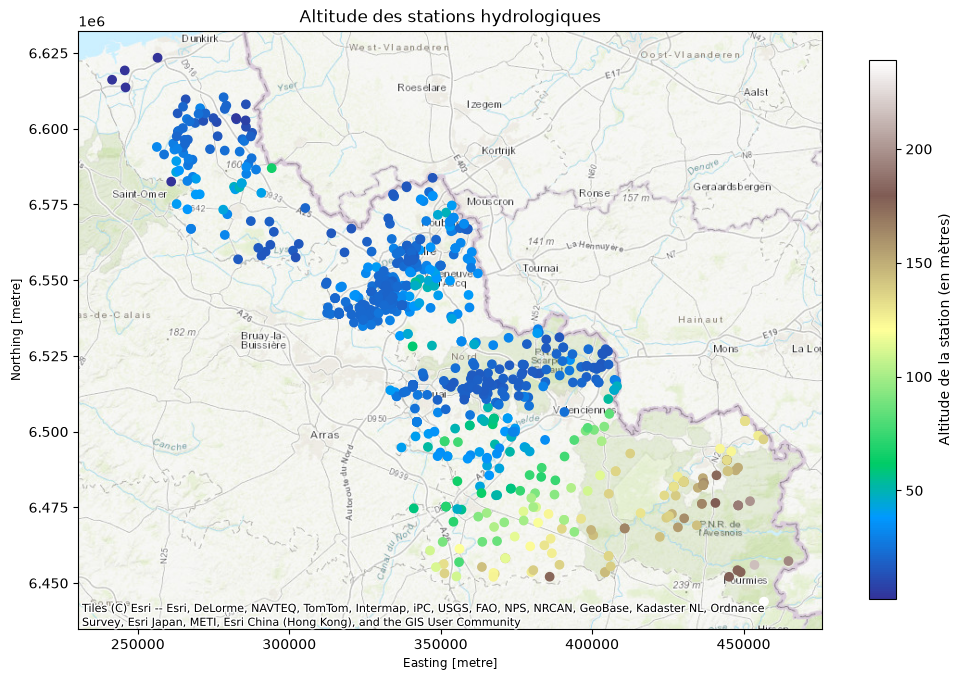

In [36]:
stations['altitude_station'] = pd.to_numeric(stations['altitude_station'])
points_carte = stations.to_crs(epsg=3857)   #on transforme le geopandas avec le code EPSG utilisé par les cartes et Google

fig, ax = plt.subplots(figsize=(12, 10))
points_carte.plot(ax=ax,
    column='altitude_station', # variable qui donne la couleur du point
    cmap='terrain', # fond de carte pour la topographie
    legend=True,                 # Affichage de la barre de gradient
    legend_kwds={
        'label': "Altitude de la station (en mètres)",
        'shrink': 0.7   #Limite la taille de la barre de la légende
    },
    zorder=2
)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap, zorder=1)   #Fonds de carte
plt.title("Altitude des stations hydrologiques")

2. Annulation de l'effet de l'l'altitude sur le niveau des nappes.

La variable niveau_nappe_eau nous donne le niveau de l'eau de la nappe par rapport au niveau de la mer. Pas par rapport au fond de la nappe. On ne peut pas obtenir le volume d'eau dans la nappe. On ne peut qu'observer le niveau de l'eau dans la nappe.  
Nous allons donc étudier les variations du niveau de la nappe sur la moyenne historique afin de déterminer si l'industrie creuse les nappes.  
On va annuler l'effet de l'altitude sur le niveau de l'eau dans la station pour pouvoir comparer les niveau d'eau dans les différentes stations.  
Pour cela, on va centrer le niveau pour ne garder que les variations de niveau des nappes :  
Exemple : si on a en moyenne une hauteur de 100m pour une station, après une sécheresse qui fait baisser ce niveau à 90m, on aura -10 de variation sur notre chronique.

In [37]:
moyenne_par_station = chroniques.groupby("code_bss")["niveau_nappe_eau"].mean().reset_index()
moyenne_par_station = moyenne_par_station.rename(columns={"niveau_nappe_eau": "moyenne_de_station"})
chroniques = chroniques.merge(moyenne_par_station, on="code_bss", how="left")   #On rajoute la colonne dans le DataFrame de base en affectant à chaque ligne d'observation une colonne avec la moyenne de sa station

chroniques["niveau_eau_isole"] = chroniques["niveau_nappe_eau"] - chroniques["moyenne_de_station"]

print(chroniques[["code_bss", "date_mesure", "niveau_nappe_eau", "niveau_eau_isole"]].sample(15))

             code_bss date_mesure  niveau_nappe_eau  niveau_eau_isole
3238    00281X0002/F1  2024-05-01         12.484516          2.905610
4975     BSS004CFVG/X  2023-05-01          7.041613         -0.390908
1743  00202A0460/PZ12  2020-01-01         11.154194         -3.523796
5681     BSS004LJLE/X  2016-06-01         16.950000          0.716753
881    00146X2040/PZ5  2022-08-01         16.144839         -0.295786
3041   00278X0132/PZ7  2023-11-01         33.300000          0.170200
829   00146B0737/PZR2  2022-04-01         11.857000         -0.628091
3831    00291X0031/P1  2022-12-01         29.284194         -1.515635
3088   00278X0133/PZ8  2021-08-01         33.620000         -0.093590
3313    00281X0004/F1  2019-08-01         27.485484         -1.730275
5973     BSS004LJLJ/X  2020-05-01         14.560000         -0.279867
4155    00377X0051/S1  2017-01-01         92.321613          0.391399
5263     BSS004GZEL/X  2025-01-01         17.270000          1.130989
5868     BSS004LJLF/

## 2. Prise en compte de l'effet de la nature des sols

On va vérifier si l'effet de la géologie doit être pris en compte.  
En effet, on peut supposer que selon la nature du sol, les nappes phréatiques peuvent se vider plus ou moins rapidement et les variations de niveau peuvent donc être impactés.  
Il y a de nombreux types de sols. On va donc se concentrer sur les 5 les plus courants pour vérifier notre hypothèse  

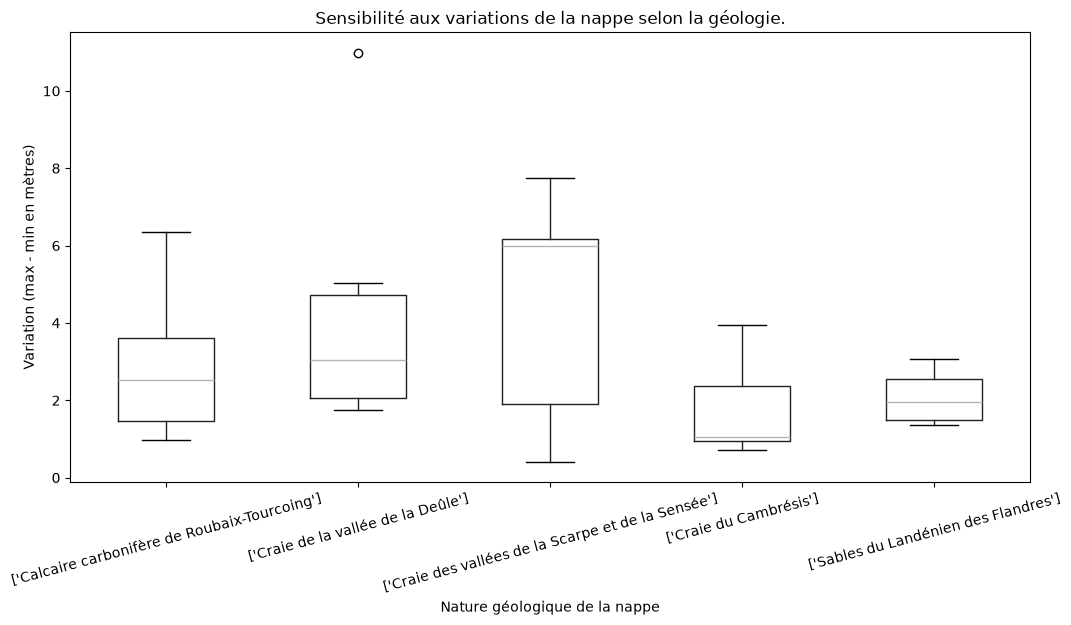

In [38]:
#Nettoyage de type :
stations['noms_masse_eau_edl'] = stations['noms_masse_eau_edl'].astype(str)

#Calcul des variations du niveau de chaque nappe
amplitude = chroniques.groupby('code_bss')['niveau_nappe_eau'].agg(lambda x: x.max() - x.min()).reset_index()
amplitude = amplitude.rename(columns={'niveau_nappe_eau': 'amplitude_metres'})
stations = stations.merge(amplitude, on='code_bss', how='inner')

#On prend les 5 sols les plus fréquents
compte = stations.groupby('noms_masse_eau_edl').size()
tri = compte.sort_values(ascending=False)
top_5_sols = tri.head(5).index

stations_top = stations[stations['noms_masse_eau_edl'].isin(top_5_sols)]
stations_top.boxplot(column='amplitude_metres', by='noms_masse_eau_edl', grid=False, rot=15, figsize=(12, 6))
plt.title("Sensibilité aux variations de la nappe selon la géologie.")
plt.suptitle("") # sinon pPandas met un sous-titre automatique
plt.ylabel("Variation (max - min en mètres)")
plt.xlabel("Nature géologique de la nappe")
plt.show()

On va créer une colonne qui met des labels sur les types géologiques. On pourra ainsi prendre en compte cet effet dans la suite de notre étude.

In [39]:
#Petit nettoyage de type
stations['noms_masse_eau_edl'] = stations['noms_masse_eau_edl'].astype(str)

#Familles de sols
conditions_geo = [
    stations['noms_masse_eau_edl'].str.contains('Craie', case=False, na=False),
    stations['noms_masse_eau_edl'].str.contains('Sable|Landénien', case=False, na=False),
    stations['noms_masse_eau_edl'].str.contains('Calcaire', case=False, na=False)
]
labels_type_station = ['Craie (Forte amplitude)', 'Sable (Faible amplitude)', 'Calcaire (Amplitude modérée)']

#On ajoute la colonne au dataframe
stations['famille_geologique'] = np.select(conditions_geo, labels_type_station, default='Autre')
print(stations['famille_geologique'].value_counts())

famille_geologique
Craie (Forte amplitude)         31
Autre                           17
Calcaire (Amplitude modérée)    11
Sable (Faible amplitude)         8
Name: count, dtype: int64


Après vérification, dans la catégorie autre, on ne retrouve quasiment que des types de sols NaN.

## 3. Prise en compte de l'effet de la topologie (distance entre la surface et la nappe)

On va vérifier si l'effet de la topologie a un effet (à annuler pour notre analyse) sur le niveau des nappes phréatiques

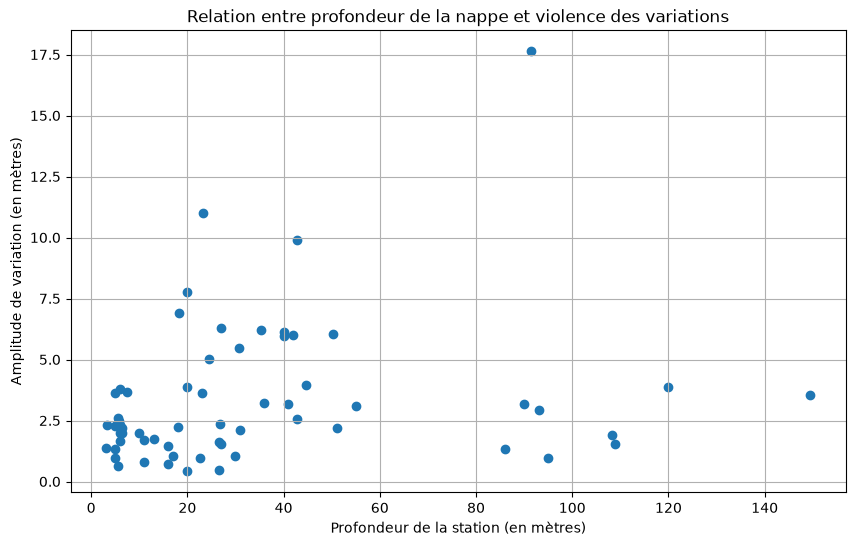

In [40]:
plt.figure(figsize=(10, 6))
# On limite l'axe X à 150m pour ne pas écraser le graphique avec les extrêmes
donnees_visuelles = stations[stations['profondeur_investigation'] < 150]

plt.scatter(donnees_visuelles['profondeur_investigation'], donnees_visuelles['amplitude_metres'])
plt.title("Relation entre profondeur de la nappe et violence des variations")
plt.xlabel("Profondeur de la station (en mètres)")
plt.ylabel("Amplitude de variation (en mètres)")
plt.grid(True)
plt.show()

In [41]:
#Nouvelle colonne qui donne un label topologie à la station
stations['classe_profondeur'] = 'Non renseignée'

stations.loc[stations['profondeur_investigation'] < 30, 'classe_profondeur'] = 'Superficielle (<30m)'
stations.loc[(stations['profondeur_investigation'] >= 30) & (stations['profondeur_investigation'] <= 80), 'classe_profondeur'] = 'Intermédiaire (30-80m)'
stations.loc[stations['profondeur_investigation'] > 80, 'classe_profondeur'] = 'Profonde (>80m)'

print(stations['classe_profondeur'].value_counts())

classe_profondeur
Superficielle (<30m)      40
Intermédiaire (30-80m)    15
Profonde (>80m)           12
Name: count, dtype: int64


On voit qu'on a 40 stations superficielles qui devraient être les plus affectées par les installations industrielles.  
Le groupe des stations profondes qui ne devraient pas être très affectées par l'activité industrielle servira de groupe témoin.

## Recentrage sur les stations intéressantes
On remarque qu'on n'a plus que environ 70 stations alors qu'on en avait 730 au début.  
Cela est dû au inner join fait pour catégoriser les stations selon la géologie (avec le calcul de l'amplitude pour chaque type de sol).  
Vérifions à quoi ressemble les stations éliminées et leurs chroniques pour comprendre.

In [42]:
#On reprend la liste de toutes les stations
stations_brutes = pd.read_csv("../../data/stations_nappes.csv") 

codes_valides = chroniques['code_bss'].unique() #Stations qui ont été conservées dans le processus.
print("Stations conservées dans l'analyse : ", len(codes_valides))
print(stations[['code_bss', 'nom_commune', 'nb_mesures_piezo']].sort_values(by="nb_mesures_piezo", ascending=False).head(10))
stations_eliminees = stations_brutes[~stations_brutes['code_bss'].isin(codes_valides)]

#On regarde le nombre de mesures pour les stations éliminées :
print("Stations éliminées : ", len(stations_eliminees))
print(stations_eliminees[['code_bss', 'nom_commune', 'nb_mesures_piezo']].sort_values(by="nb_mesures_piezo", ascending=False).head(10))

Stations conservées dans l'analyse :  67
            code_bss            nom_commune  nb_mesures_piezo
30    00216X0073/PZ3               Lecelles             17017
7      00146B0007/F1                  Lille             15483
10     00143C0079/F1                Bondues             15183
14     00147D0218/P1                  Lille             13224
25     00148D0177/F2               Baisieux              9802
13     00291X0031/P1  Rombies-et-Marchipont              9210
24    00225X0077/FC2     Fresnes-sur-Escaut              9003
16     00217X0068/P1    Flines-lès-Mortagne              8614
6      00281X0004/F1                 Abscon              8609
1   00387X0184/PZCC1             Grand-Fayt              8596
Stations éliminées :  663
          code_bss          nom_commune  nb_mesures_piezo
260  00215X0140/P1           Bouvignies              9084
273  00225X0061/P1              Crespin              8236
78   00143B0102/F1            Tourcoing              6850
146  00281X0065/F1 

Donc on a un problème manifestement.  
Il est possible que les stations éliminées sont des stations qui n'ont pas enregistré de données entre 2015 et 2026 (car le nb_mesures_piezo est le nombre de mesures totales depuis la création de la station).

In [43]:
stations_eliminees['date_fin_mesure'] = pd.to_datetime(stations_eliminees['date_fin_mesure'])
#on regarde l'année d'arrêt de la station
stations_eliminees['annee_arret'] = stations_eliminees['date_fin_mesure'].dt.year

# On affiche l'année de fin d'activité pour les 10 plus grosses stations éliminées
colonnes_visibles = ['code_bss', 'nom_commune', 'nb_mesures_piezo', 'annee_arret']
print(stations_eliminees.sort_values(by="nb_mesures_piezo", ascending=False)[colonnes_visibles].head(10))

arret_avant_2015 = len(stations_eliminees[stations_eliminees['annee_arret'] < 2015])
jamais_mesure = len(stations_eliminees[stations_eliminees['annee_arret'].isna()])
print("Stations arrêtées définitivement avant 2015 : ", arret_avant_2015)
print("Stations sans date de fin : ", jamais_mesure)

print(stations_eliminees.loc[stations_eliminees['annee_arret'].isna()].sort_values(by="nb_mesures_piezo", ascending=False)[colonnes_visibles].head(10))

          code_bss          nom_commune  nb_mesures_piezo  annee_arret
260  00215X0140/P1           Bouvignies              9084       2004.0
273  00225X0061/P1              Crespin              8236       1996.0
78   00143B0102/F1            Tourcoing              6850       1996.0
146  00281X0065/F1              Rieulay              6676       2001.0
258  00385X0010/P1  Catillon-sur-Sambre              6617       2001.0
165  00201C0126/F1               Provin              6581       2004.0
131  00144C0005/F1            Wattrelos              6465       1987.0
413  00274X0014/F2              Anhiers              4762       2006.0
57   00273X0151/F1                Douai              4480       1997.0
307  00035X0045/P1           Loon-Plage              4260       1983.0
Stations arrêtées définitivement avant 2015 :  633
Stations sans date de fin :  30
           code_bss        nom_commune  nb_mesures_piezo  annee_arret
107   00207X0153/F1     Roost-Warendin                 0          

Donc c'est tout bon : seules les 67 stations gardées sont encore actives après 2015 et rentrent dans le cadre de notre étude.

## Conclusion partielle
On a annulé l'effet de l'altitude.  
On a segmenté les stations selon la géologie pour vérifier qu'elles ne biaisent pas les observations futures.  
On a segmenté les stations en un groupe expérience (stations superficielles affectées par l'industrie) et un groupe test (stations profondes).

# II. On va ensuite prendre en compte l'effet de la pluie

Avec le cycle naturel de l'eau, il est normal que l'eau joue un rôle important dans la variation du niveau des nappes phréatiques.  
Nous allons donc vérifier si cela peut impacter notre enquête.

In [44]:
url_1950_2024 = "https://www.data.gouv.fr/api/1/datasets/r/c2a9f75c-0554-48d6-ba1a-534b00063f89"
url_2025_2026 = "https://www.data.gouv.fr/api/1/datasets/r/e356abd8-90ff-4c7f-a0cd-55661c3be402"

chemin_1950_2024 = "../../data/meteo_59_1950_2024.csv.gz"
chemin_2025_2026 = "../../data/meteo_59_2025_2026.csv.gz"

os.makedirs("../../data", exist_ok=True)
fichiers_a_telecharger = [
    (url_1950_2024, chemin_1950_2024),
    (url_2025_2026, chemin_2025_2026)
]

for url, nom_fichier in fichiers_a_telecharger:
    if not os.path.exists(nom_fichier):
        reponse = rq.get(url)
        with open(nom_fichier, "wb") as fichier:
            fichier.write(reponse.content)
        print("Téléchargement terminé.")

meteo_1950_2024 = pd.read_csv(chemin_1950_2024, sep=";", compression="gzip")
meteo_2025_2026 = pd.read_csv(chemin_2025_2026, sep=";", compression="gzip")

# On enlève toutes les données avant 2015 pour ne garder que la période 2015-2026
meteo_2015_2024 = meteo_1950_2024[meteo_1950_2024["AAAAMMJJ"] >= 20150101]
meteo = pd.concat([meteo_2015_2024, meteo_2025_2026], ignore_index=True)

# Nettoyage : mise en forme de la date
meteo["date"] = pd.to_datetime(meteo["AAAAMMJJ"].astype(str), format="%Y%m%d")

print(meteo[["NUM_POSTE", "NOM_USUEL", "LAT", "LON", "ALTI", "date", "RR", "TM"]].head(5))

   NUM_POSTE    NOM_USUEL      LAT     LON  ALTI       date    RR  TM
0   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-01   0.3 NaN
1   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-02   1.0 NaN
2   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-03  11.0 NaN
3   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-04   0.6 NaN
4   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-05   0.0 NaN


Aux développeurs :  
Objectifs de cette partie : identifier les périodes de sécheresse, vérifier dans quelle mesure les variations des niveaux des nappes phréatiques s'explique par la pluie
Procédé : coupler les stations de météo aux stations de nappes, prendre en compte que la pluie arrive dans les nappes après au moins 2 semaines (selon la profondeur de la nappe (cf partie 1)

# III. Effet de l'industrie sur les nappes phréatiques

Objectif : déterminer si les nappes situées près des installations industrielles ont évolué plus défavorablement que les autres entre 2015 et 2025.

Démarche :
1. Mesurer l'évolution de chaque nappe entre le début et la fin de la période.
2. Mesurer la pression industrielle autour de chaque station (nombre d'usines).
3. Comparer les deux, puis chercher ce qui distingue les stations (géologie, profondeur).
4. Vérifier avec les volumes d'eau réellement pompés (BNPE).

## 1. Mesure de l'évolution des nappes

Pour chaque station, on compare le niveau moyen de 2015-2017 à celui de 2023-2025.

- On travaille sur des moyennes annuelles : chaque année contient un hiver et un été, ce qui évite de comparer une valeur d'été à une valeur d'hiver (qui sont toujours différentes à cause de la saisonalité).
- On ne garde que les années quasi complètes (au moins 10 mois mesurés).
- On compare des moyennes sur trois ans plutôt qu'une seule année, car une année isolée peut être exceptionnellement sèche ou humide et fausser le résultat.
- On exige au moins deux années valides dans chaque période.


In [62]:
#On crée un tableau qui va contenir l'évolution (variation moyenne debut et moyenne fin) de chaque station.
chroniques["annee"] = chroniques["date_mesure"].dt.year
annuel = chroniques.groupby(["code_bss", "annee"]).agg(niveau=("niveau_nappe_eau", "mean"), nb_mois=("niveau_nappe_eau", "size")).reset_index()
annuel = annuel[annuel["nb_mois"] >= 10]

debut = annuel[annuel["annee"].between(2015, 2017)].groupby("code_bss")["niveau"].agg(["mean", "size"])
fin = annuel[annuel["annee"].between(2023, 2025)].groupby("code_bss")["niveau"].agg(["mean", "size"])

evo = debut.join(fin, suffixes=("_debut", "_fin"), how="inner")
evo = evo[(evo["size_debut"] >= 2) & (evo["size_fin"] >= 2)]
evo["evolution_m"] = evo["mean_fin"] - evo["mean_debut"]

print("Stations avec une évolution calculable :", len(evo))

Stations avec une évolution calculable : 50


In [ ]:
# On crée le tableau de travail avec les données sur les stations (profondeur, géologie, evolution)
st = stations.merge(evo[["mean_debut", "evolution_m"]].reset_index(), on="code_bss")

st["profondeur_investigation"] = pd.to_numeric(st["profondeur_investigation"], errors="coerce")
st["classe_profondeur"] = pd.cut(st["profondeur_investigation"], bins=[-np.inf, 30, 80, np.inf], labels=["Superficielle (<30m)", "Intermédiaire (30-80m)", "Profonde (>80m)"])

noms = st["noms_masse_eau_edl"].astype(str)
st["famille_geologique"] = np.select(
    [noms.str.contains("Craie", case=False), noms.str.contains("Sable|Landénien", case=False), noms.str.contains("Calcaire", case=False)],
    ["Craie", "Sable", "Calcaire"],
    default="Autre"
)

print(st["evolution_m"].describe().round(2))

count    50.00
mean     -0.05
std       0.75
min      -3.57
25%      -0.18
50%       0.06
75%       0.16
max       2.72
Name: evolution_m, dtype: float64


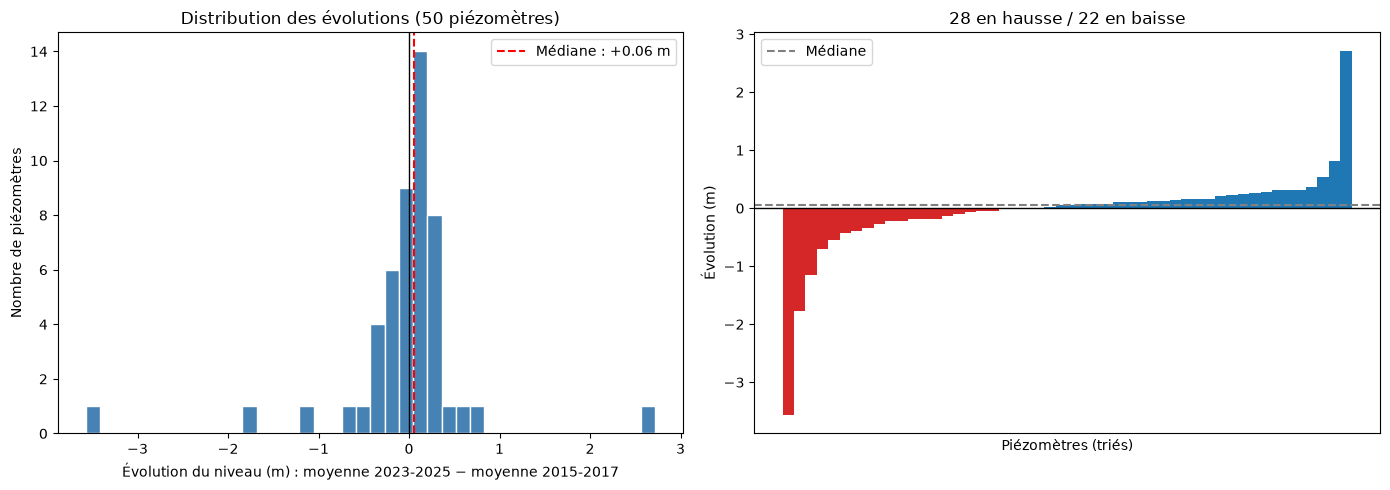

In [ ]:
# Affichage de la distribution des évolutions des stations
med = st["evolution_m"].median()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(st["evolution_m"], bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].axvline(med, color="red", linestyle="--", label=f"Médiane : {med:+.2f} m")
axes[0].set_xlabel("Évolution du niveau (m) : moyenne 2023-2025 − moyenne 2015-2017")
axes[0].set_ylabel("Nombre de piézomètres")
axes[0].set_title(f"Distribution des évolutions ({len(st)} piézomètres)")
axes[0].legend()

tri = st["evolution_m"].sort_values().reset_index(drop=True)
axes[1].bar(tri.index, tri, width=1, color=np.where(tri < 0, "tab:red", "tab:blue"))
axes[1].axhline(0, color="black", linewidth=1)
axes[1].axhline(med, color="grey", linestyle="--", label="Médiane")
axes[1].set_xticks([])
axes[1].set_xlabel("Piézomètres (triés)")
axes[1].set_ylabel("Évolution (m)")
axes[1].set_title(f"{(tri > 0).sum()} en hausse / {(tri < 0).sum()} en baisse")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interprétation.** Sur les 50 piézomètres étudiés, la médiane de l'évolution est de +0,06 m : la nappe typique du Nord est au même niveau en 2023-2025 qu'en 2015-2017. La grande majorité des stations varie de moins de 50 cm, et la répartition entre hausses (28) et baisses (22) est presque équilibrée. Il n'y a donc pas de baisse généralisée des nappes dans le département.

Quelques stations s'écartent nettement : trois fortes baisses (Bondues −3,57 m, Nieppe −1,76 m, Villers-en-Cauchies −1,16 m) et une forte hausse (Limont-Fontaine +2,72 m).


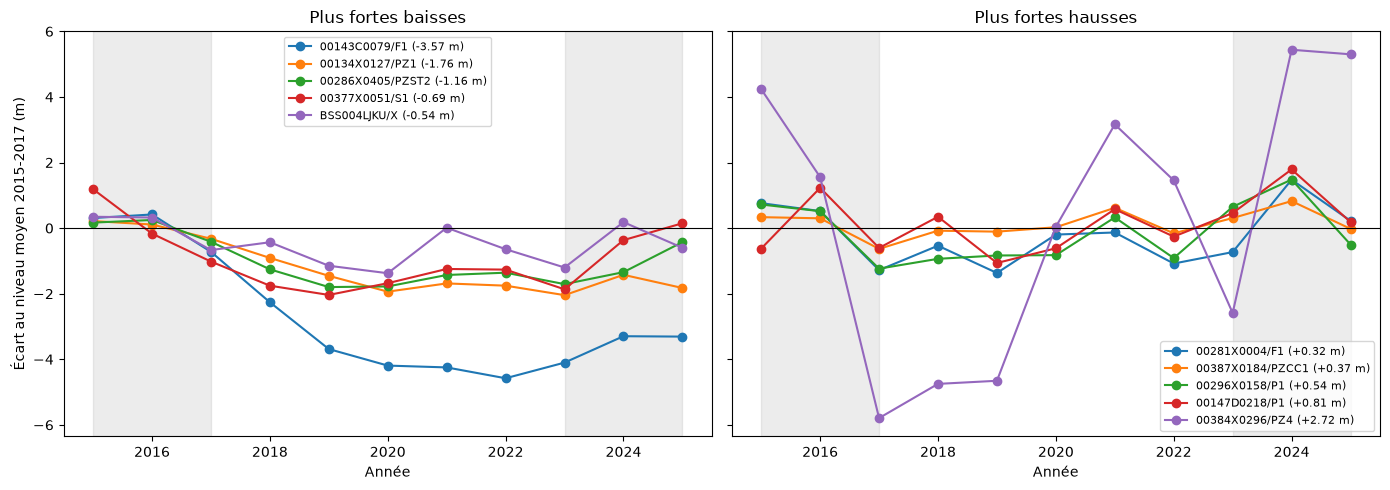

In [ ]:
#Affichage des plus grandes evolutions au cours du temps en séparant les stations en fonction de si elles
#ont subit une baisse ou une hausse
annuel_ecart = annuel.merge(evo[["mean_debut"]], left_on="code_bss", right_index=True)
annuel_ecart["ecart"] = annuel_ecart["niveau"] - annuel_ecart["mean_debut"]

tri_st = st.sort_values("evolution_m")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, codes, titre in [(axes[0], tri_st["code_bss"].head(5), "Plus fortes baisses"), (axes[1], tri_st["code_bss"].tail(5), "Plus fortes hausses")]:
    for code in codes:
        serie = annuel_ecart[annuel_ecart["code_bss"] == code]
        evol = st.loc[st["code_bss"] == code, "evolution_m"].iloc[0]
        ax.plot(serie["annee"], serie["ecart"], marker="o", label=f"{code} ({evol:+.2f} m)")
    ax.axvspan(2015, 2017, color="grey", alpha=0.15)
    ax.axvspan(2023, 2025, color="grey", alpha=0.15)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(titre)
    ax.set_xlabel("Année")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Écart au niveau moyen 2015-2017 (m)")
plt.tight_layout()
plt.show()

**Interprétation.** Presque toutes les stations suivent un mouvement commun : une baisse de 2017 à 2019-2020, puis une remontée en 2024. C'est la signature du climat (années sèches, puis hiver 2023-2024 très pluvieux), qui touche toutes les nappes.

Bondues (bleu) se distingue : elle descend jusqu'à −4,5 m en 2022 et remonte peu. Un autre facteur semble s'ajouter au climat pour cette station.

Plusieurs stations « en hausse » ne le sont que grâce à l'année 2024, exceptionnellement humide : l'indicateur dépend en partie du choix des périodes.

La station de Limont-Fontaine (violet) varie de plus de 11 m, bien plus que ses voisines : ses données sont atypiques et doivent être interprétées avec prudence.

## 2. Premier indicateur de pression : le nombre d'usines

On ne garde que l'industrie manufacturière (codes NAF 10 à 33) et l'énergie (code 35), qui sont les activités les plus consommatrices d'eau. Pour chaque station, on compte les usines situées à moins de 2, 5 et 10 km, afin de vérifier que le résultat ne dépend pas du rayon choisi.

Les stations sont ensuite réparties en trois groupes : 0 usine, 1 à 5 usines, plus de 5 usines (dans un rayon de 5 km).

In [75]:
# On ne garde que l'industrie manufacturière et l'énergie
code_naf = pd.to_numeric(installations_indust["code_naf"].astype(str).str[:2], errors="coerce")
usines = installations_indust[code_naf.between(10, 33) | (code_naf == 35)]
print("Usines manufacturières et énergétiques retenues :", len(usines))

#On compte les usines à procximité de chaque station avec différents rayons
for r in [2, 5, 10]:
    st[f"usines_{r}km"] = st.geometry.apply(lambda g: (usines.distance(g) <= r * 1000).sum())

#On sépare les stations en fonction de la pression industrielle (=nb d'usines aux alentour) qu'elles subissent
st["pression"] = pd.cut(st["usines_5km"], bins=[-1, 0, 5, 10000], labels=["0 usine", "1 à 5 usines", "plus de 5 usines"])
print(st["pression"].value_counts())

Usines manufacturières et énergétiques retenues : 428
pression
1 à 5 usines        24
plus de 5 usines    20
0 usine              6
Name: count, dtype: int64


                  count  mean   std   min   25%   50%   75%   max
pression                                                         
0 usine             6.0 -0.08  0.61 -1.16 -0.26  0.04  0.30  0.54
1 à 5 usines       24.0  0.05  0.62 -0.69 -0.19  0.01  0.10  2.72
plus de 5 usines   20.0 -0.15  0.94 -3.57 -0.09  0.14  0.24  0.81


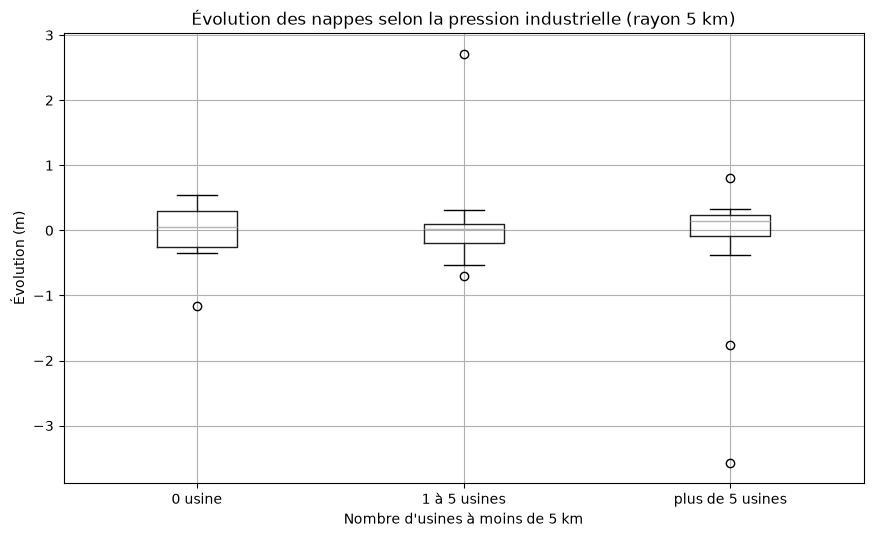

In [76]:
# Affichons en boxplot l'evolution pour chaque type de pression
print(st.groupby("pression")["evolution_m"].describe().round(2))

st.boxplot(column="evolution_m", by="pression", figsize=(10, 6))
plt.suptitle("")
plt.title("Évolution des nappes selon la pression industrielle (rayon 5 km)")
plt.xlabel("Nombre d'usines à moins de 5 km")
plt.ylabel("Évolution (m)")
plt.show()

**Interprétation.** Les trois boîtes sont centrées autour de zéro et ont des tailles comparables. Les médianes sont de +0,04 m (0 usine), +0,01 m (1 à 5 usines) et +0,14 m (plus de 5 usines) : des écarts de l'ordre du centimètre ou de la dizaine de centimètres, négligeables. La station typique évolue de la même façon, qu'elle ait 0 ou 15 usines autour d'elle. Le groupe le plus industriel a même la médiane la plus élevée.

La dispersion centrale ne diffère pas non plus : l'écart interquartile vaut 0,56 m sans usine, 0,29 m pour 1 à 5 usines et 0,33 m pour plus de 5 usines. Dans le groupe le plus industriel, les trois quarts des stations ont une évolution supérieure à −0,09 m.

La moyenne du groupe « plus de 5 usines » (−0,15 m) est pourtant la plus basse, alors que sa médiane est la plus haute. Cet écart vient de deux valeurs extrêmes, Bondues (−3,57 m) et Nieppe (−1,76 m), qui tirent la moyenne vers le bas et gonflent l'écart-type (0,94 m contre environ 0,6 m dans les autres groupes). C'est pourquoi on commente la médiane : la moyenne laisserait croire à un effet de l'industrie dû à seulement deux stations.

Les autres valeurs isolées sont Villers-en-Cauchies (−1,16 m), une baisse sans aucune usine à proximité, Lille (+0,81 m), une hausse malgré une forte présence industrielle, et Limont-Fontaine (+2,72 m), dont les données sont atypiques.

Le groupe « 0 usine » ne compte que 6 stations : ses statistiques sont à interpréter avec prudence.

In [77]:
for r in [2, 5, 10]:
    print(f"Spearman évolution / usines à {r} km :", round(st["evolution_m"].corr(st[f"usines_{r}km"], method="spearman"), 2))

Spearman évolution / usines à 2 km : 0.25
Spearman évolution / usines à 5 km : 0.15
Spearman évolution / usines à 10 km : 0.17


**Interprétation.** On utilise la corrélation de Spearman, qui travaille sur les rangs : elle mesure si « plus d'usines » va avec « plus de baisse », sans être dominée par quelques valeurs extrêmes.

Elle vaut 0,25 à 2 km, 0,15 à 5 km et 0,17 à 10 km. Ces valeurs sont faibles et positives : on ne trouve aucune relation négative entre le nombre d'usines et l'évolution des nappes. Le résultat est stable quel que soit le rayon, ce qui le rend robuste.

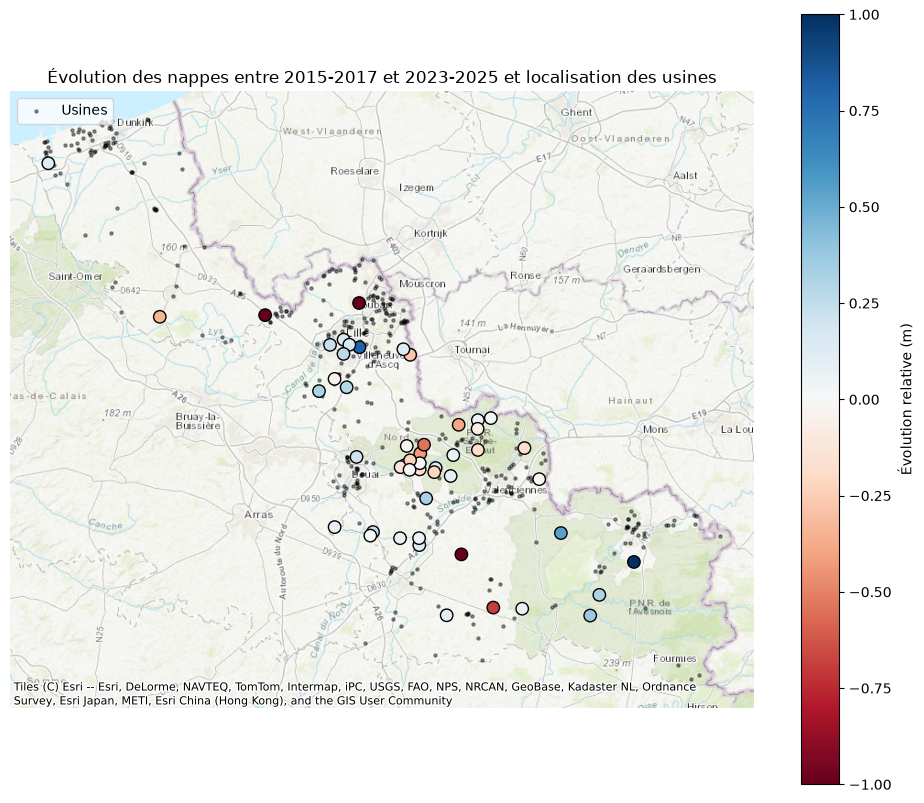

In [ ]:
# Affichons sur une carte les stations et leur évolution 
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(12, 10))
usines.to_crs(epsg=3857).plot(ax=ax, color="black", markersize=5, alpha=0.4, label="Usines", zorder=2)
st.to_crs(epsg=3857).plot(ax=ax, column="evolution_m", cmap="RdBu", norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1), markersize=80, edgecolor="black", legend=True, legend_kwds={"label": "Évolution relative (m)"}, zorder=3)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap, zorder=1)
ax.set_axis_off()
plt.legend(loc="upper left")
plt.title("Évolution des nappes entre 2015-2017 et 2023-2025 et localisation des usines")
plt.show()

**Interprétation.** Les stations en baisse (rouge) et en hausse (bleu) sont réparties dans tout le département, sans concentration particulière autour des pôles industriels. Dans la métropole lilloise, où les usines sont les plus denses, la plupart des stations sont stables ou en hausse. Bondues, au nord de Lille, fait exception.

## 3. Ce qui distingue les stations en baisse

Puisque l'industrie n'explique pas les différences entre stations dans notre échantillon, on regarde les caractéristiques des stations extrêmes, puis l'effet de la géologie et de la profondeur.

In [79]:
colonnes = ["code_bss", "nom_commune", "evolution_m", "usines_5km", "classe_profondeur", "famille_geologique"]
print("Plus fortes baisses")
print(st.sort_values("evolution_m")[colonnes].head(8).to_string(index=False))
print("\nPlus fortes hausses")
print(st.sort_values("evolution_m")[colonnes].tail(5).to_string(index=False))

Plus fortes baisses
        code_bss         nom_commune  evolution_m  usines_5km      classe_profondeur famille_geologique
   00143C0079/F1             Bondues    -3.568473          21        Profonde (>80m)           Calcaire
  00134X0127/PZ1              Nieppe    -1.764613          11 Intermédiaire (30-80m)              Sable
00286X0405/PZST2 Villers-en-Cauchies    -1.159201           0   Superficielle (<30m)              Craie
   00377X0051/S1            Neuvilly    -0.694987           3 Intermédiaire (30-80m)              Craie
    BSS004LJKU/X     Beuvry-la-Forêt    -0.539708           5   Superficielle (<30m)              Autre
 00215X0187/PZAE         Marchiennes    -0.424632           2   Superficielle (<30m)              Sable
  00216X0073/PZ3            Lecelles    -0.385997          10 Intermédiaire (30-80m)              Craie
   00124X0023/F1         Steenbecque    -0.340717           0        Profonde (>80m)              Sable

Plus fortes hausses
        code_bss     no

**Interprétation.** Les deux plus fortes baisses sont entourées de nombreuses usines (Bondues : 21, Nieppe : 11), mais Villers-en-Cauchies (−1,16 m) et Steenbecque n'en ont aucune. À l'inverse, Lille, avec 22 usines, fait partie des plus fortes hausses (+0,81 m).

Bondues et Lille ont presque le même nombre d'usines mais des évolutions opposées. Ce qui les distingue est le type de nappe : Bondues est une nappe profonde dans le calcaire, Lille une nappe superficielle dans la craie.

classe_profondeur   Superficielle (<30m)  Intermédiaire (30-80m)  \
famille_geologique                                                 
Autre                                 14                       0   
Calcaire                               0                       1   
Craie                                 15                       9   
Sable                                  3                       1   
All                                   32                      11   

classe_profondeur   Profonde (>80m)  All  
famille_geologique                        
Autre                             0   14  
Calcaire                          6    7  
Craie                             0   24  
Sable                             1    5  
All                               7   50  
                    count  mean   std   min   25%   50%   75%   max
famille_geologique                                                 
Autre                14.0 -0.08  0.18 -0.54 -0.17 -0.05  0.04  0.15
Calcaire          

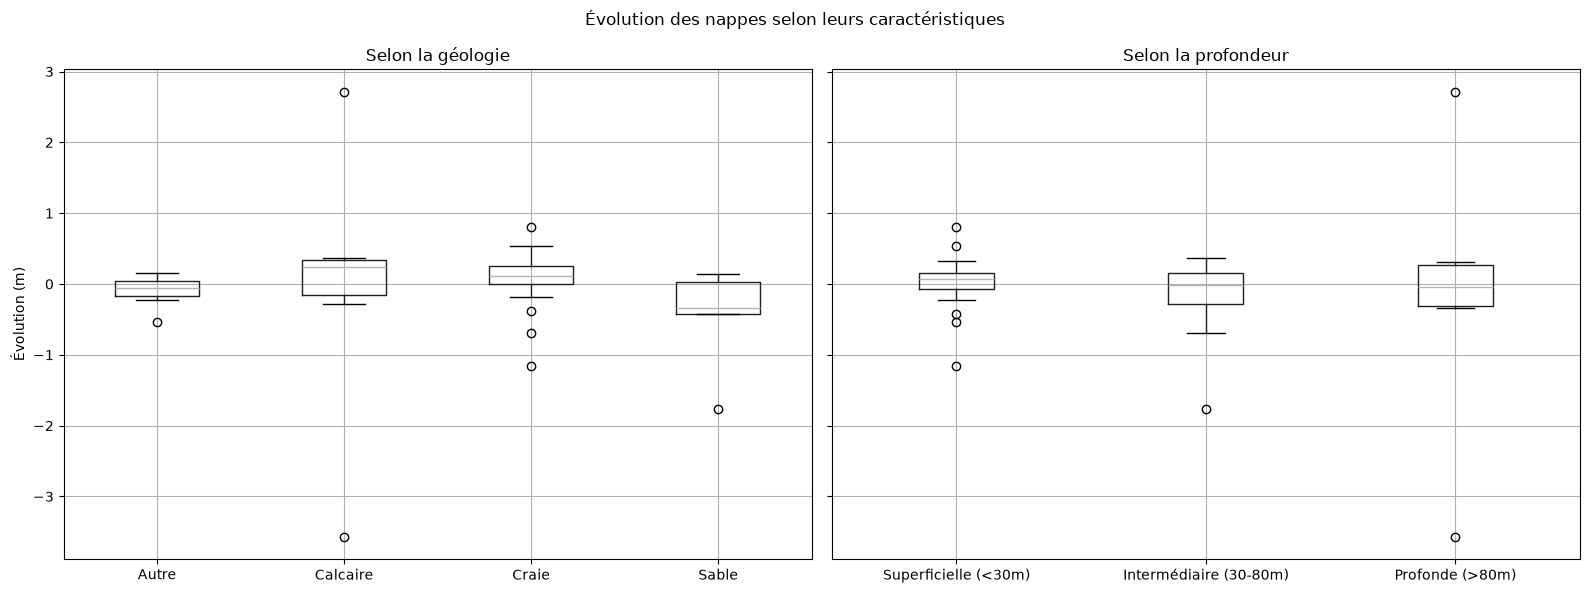

In [80]:
print(pd.crosstab(st["famille_geologique"], st["classe_profondeur"], margins=True))
print(st.groupby("famille_geologique")["evolution_m"].describe().round(2))
print(st.groupby("classe_profondeur")["evolution_m"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
st.boxplot(column="evolution_m", by="famille_geologique", ax=axes[0])
st.boxplot(column="evolution_m", by="classe_profondeur", ax=axes[1])
axes[0].set_title("Selon la géologie")
axes[1].set_title("Selon la profondeur")
axes[0].set_xlabel("")
axes[1].set_xlabel("")
axes[0].set_ylabel("Évolution (m)")
plt.suptitle("Évolution des nappes selon leurs caractéristiques")
plt.tight_layout()
plt.show()

**Interprétation : la géologie.** C'est le facteur qui différencie le plus les nappes.

- **Craie** (24 stations) : nappes stables ou en légère hausse (médiane +0,12 m), avec peu de dispersion.
- **Sable** (5 stations) : seul groupe en baisse nette (médiane −0,34 m), dont Nieppe (−1,76 m). Résultat fragile vu le faible effectif.
- **Calcaire** (7 stations) : médiane positive (+0,23 m), mais le groupe contient les deux valeurs les plus extrêmes du département, Bondues (−3,57 m) et Limont-Fontaine (+2,72 m).
- **Autre** (14 stations) : géologie non renseignée, groupe non interprétable.

L'écart entre les médianes atteint 0,57 m selon la géologie, contre 0,13 m selon la pression industrielle : le type de nappe compte davantage que le nombre d'usines.

**Interprétation : la profondeur.** Les médianes sont toutes proches de zéro : la profondeur ne change pas l'évolution typique. En revanche, plus la nappe est profonde, plus les évolutions sont dispersées (écart-type de 0,33 m en surface contre 1,84 m en profondeur). Les nappes superficielles sont les plus stables, contrairement à l'hypothèse de départ.

**Attention :** 6 des 7 stations profondes sont aussi calcaires. On ne peut donc pas séparer l'effet de la profondeur de celui de la géologie. Les groupes sable, calcaire et profond comptent 5 à 7 stations : leurs résultats sont des tendances à confirmer.

## 4. Deuxième indicateur de pression : les volumes pompés

Le nombre d'usines est un indicateur imparfait : une petite usine et une aciérie comptent pareil, et une usine ne pompe pas forcément dans la nappe. Pour vérifier que l'absence de lien ne vient pas de ce choix d'indicateur, on utilise les volumes réellement prélevés.

La BNPE (Banque Nationale des Prélèvements quantitatifs en Eau) recense, pour chaque ouvrage (forage, puits, prise d'eau) et chaque année, le volume prélevé et son usage. Ces données proviennent des déclarations des préleveurs à l'Agence de l'eau Artois-Picardie, au-delà d'un seuil de déclaration.

In [ ]:
# On télécharge les données sur les prelèvements
url_bnpe = "https://hubeau.eaufrance.fr/api/v1/prelevements/chroniques"
chemin_bnpe = "../../data/prelevements_59.csv"

if not os.path.exists(chemin_bnpe):
    prelevements = []

    #comme pour le téléchargement des chroniques, les données d'extraction d'eau des usines sont trop lourdes à télécharger d'un seul coup. On va donc télécharger année après année.
    for annee in range(2015, 2026):
        url = url_bnpe
        params_api = {
            "code_departement": departement_cible,
            "annee": annee,
            "size": 2000,
            "format": "json"
        }

        while url is not None:
            try:
                reponse = rq.get(url, params=params_api, timeout=45)
            except Exception as e:
                print("Erreur... Pas grave, on recommence.")
                time.sleep(2)
                continue

            if reponse.status_code == 200 or reponse.status_code == 206:
                data = reponse.json()
                prelevements.extend(data["data"])
                url = data.get("next")
                params_api = None
                time.sleep(0.5)
            else:
                print(f"Erreur... On réessaie...")
                time.sleep(2)

        print(f"Année {annee} terminée")

    prelevements = pd.DataFrame(prelevements)
    prelevements.to_csv(chemin_bnpe, index=False, encoding="utf-8")
    print("Téléchargement réussi.")
else:
    prelevements = pd.read_csv(chemin_bnpe, encoding="utf-8")
    print("Le fichier a déjà été téléchargé.")

Année 2015 terminée
Année 2016 terminée
Année 2017 terminée
Année 2018 terminée
Année 2019 terminée
Année 2020 terminée
Année 2021 terminée
Année 2022 terminée
Année 2023 terminée
Année 2024 terminée
Année 2025 terminée
Téléchargement réussi.


# IV. Extension à l'agriculture et à l'élevage

In [ ]:
print(2)

2
